In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Customer Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Replacing blanks with 0 as tenure is 0 and no total charges are recorded

In [20]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", 0)
df["TotalCharges"] = df["TotalCharges"].astype("float")


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [25]:
df.isnull().sum().sum()

np.int64(0)

In [26]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [29]:
df["customerID"].duplicated().sum()

np.int64(0)

# Converted 0 and 1 values of senior citizen to yes/no to make it easier to understand.

In [56]:
def conv(value):
    if value == 1:
        return "yes"
    else:
        return "no"

df["SeniorCitizen"] = df["SeniorCitizen"].apply(conv)

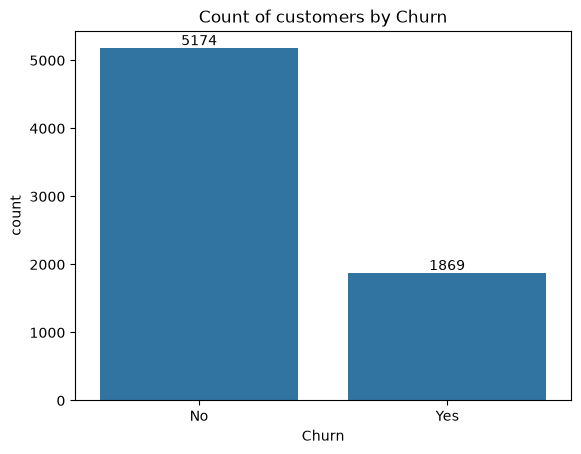

In [57]:
ax = sns.countplot(x = "Churn", data = df)

ax.bar_label(ax.containers[0])
plt.title("Count of customers by Churn")
plt.show()

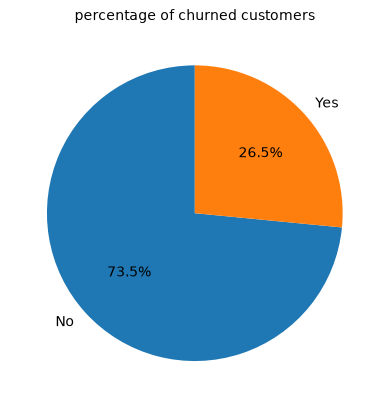

In [58]:
import matplotlib.pyplot as plt

# Using the real column name 'Churn'
df['Churn'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    startangle=90
)

plt.ylabel('')  # Removes the y-axis label for a cleaner look
plt.title("percentage of churned customers", fontsize = 10)
plt.show()

#from the given pie chart we can conclude that 26.54% of our customers have churned out. #not let's explore the reason behind it.

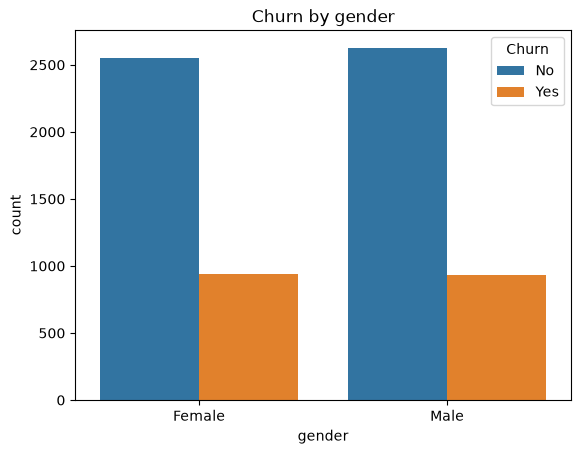

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.Figure(figsize= (3,3))
sns.countplot(x="gender", data=df, hue = "Churn")
plt.title("Churn by gender")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_15188\2732521099.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="SeniorCitizen", data=df, ax=ax, palette=['#66b3ff', '#99ff99'])


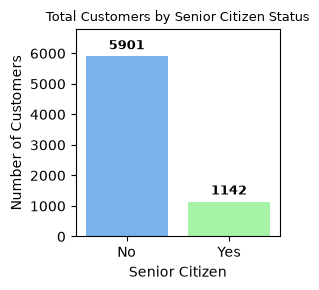

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create the count plot for SeniorCitizen only (Figure size reduced to 3x3)
fig, ax = plt.subplots(figsize=(3, 3))
sns.countplot(x="SeniorCitizen", data=df, ax=ax, palette=['#66b3ff', '#99ff99'])

# 2. Loop through the bars to add the exact count labels on top
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, fontweight='bold',
                    xytext=(0, 3),  # Shift text slightly up
                    textcoords='offset points')

# 3. Customizations
plt.title("Total Customers by Senior Citizen Status", fontsize=9)
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.ylim(0, df['SeniorCitizen'].value_counts().max() * 1.15)  # Adds a bit of space at the top for labels

plt.tight_layout()
plt.show()

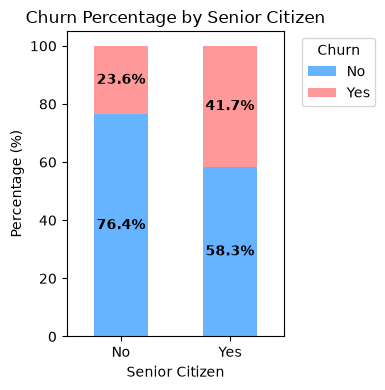

In [76]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Replace 0 with 'No' and 1 with 'Yes'
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})

# 2. Create normalized cross-tabulation table for percentages
cross_tab = pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index') * 100

# 3. Plot as a stacked bar chart (Reduced figure size to 4x4)
fig, ax = plt.subplots(figsize=(4, 4))
cross_tab.plot(kind='bar', stacked=True, ax=ax, color=['#66b3ff', '#ff9999'])

# 4. Loop through containers to add percentage labels inside the bars
for container in ax.containers:
    for p in container:
        height = p.get_height()
        if height > 3:  # Only label if segment is large enough
            x = p.get_x() + p.get_width() / 2
            y = p.get_y() + height / 2
            text = f'{height:.1f}%'
            ax.text(x, y, text, ha='center', va='center', color='black', fontsize=10, fontweight='bold')

# 5. Customizations
plt.title("Churn Percentage by Senior Citizen")
plt.xlabel("Senior Citizen")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)  # Keeps x-axis labels horizontal

plt.tight_layout()
plt.show()

#comparatively a greater percentage of people in senior citizen category have chuned

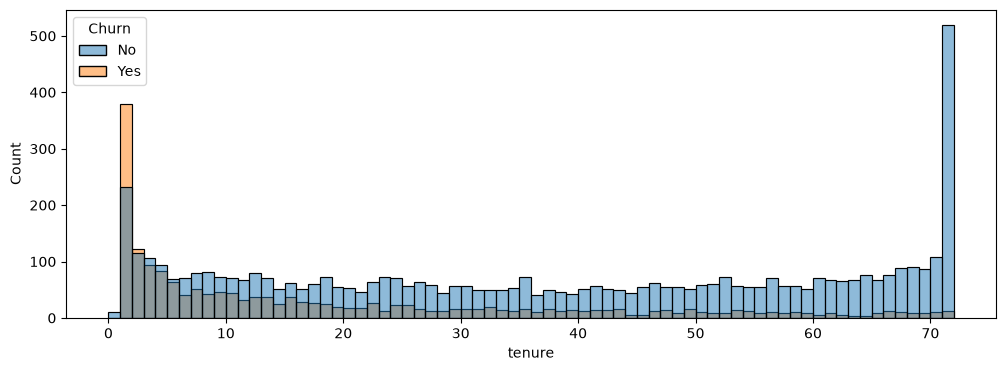

In [87]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(x = "tenure", data= df, bins= 72, hue= "Churn")
plt.show()

people who have used our services for a long time have stayed and people who have used our services for 1 0r 2 months have churned.

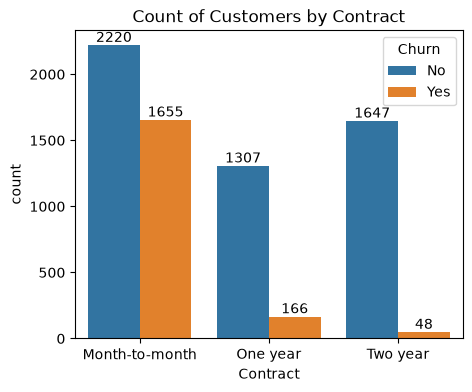

In [ ]:
plt.figure(figsize=(5,4))
ax = sns.countplot(x="Contract", data=df, hue="Churn")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Count of Customers by Contract")
plt.show()

people who have month to month contract are likely to churn then from those who have 1 or 2 years or contract.

In [13]:
df.columns.value_counts

<bound method IndexOpsMixin.value_counts of Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')>

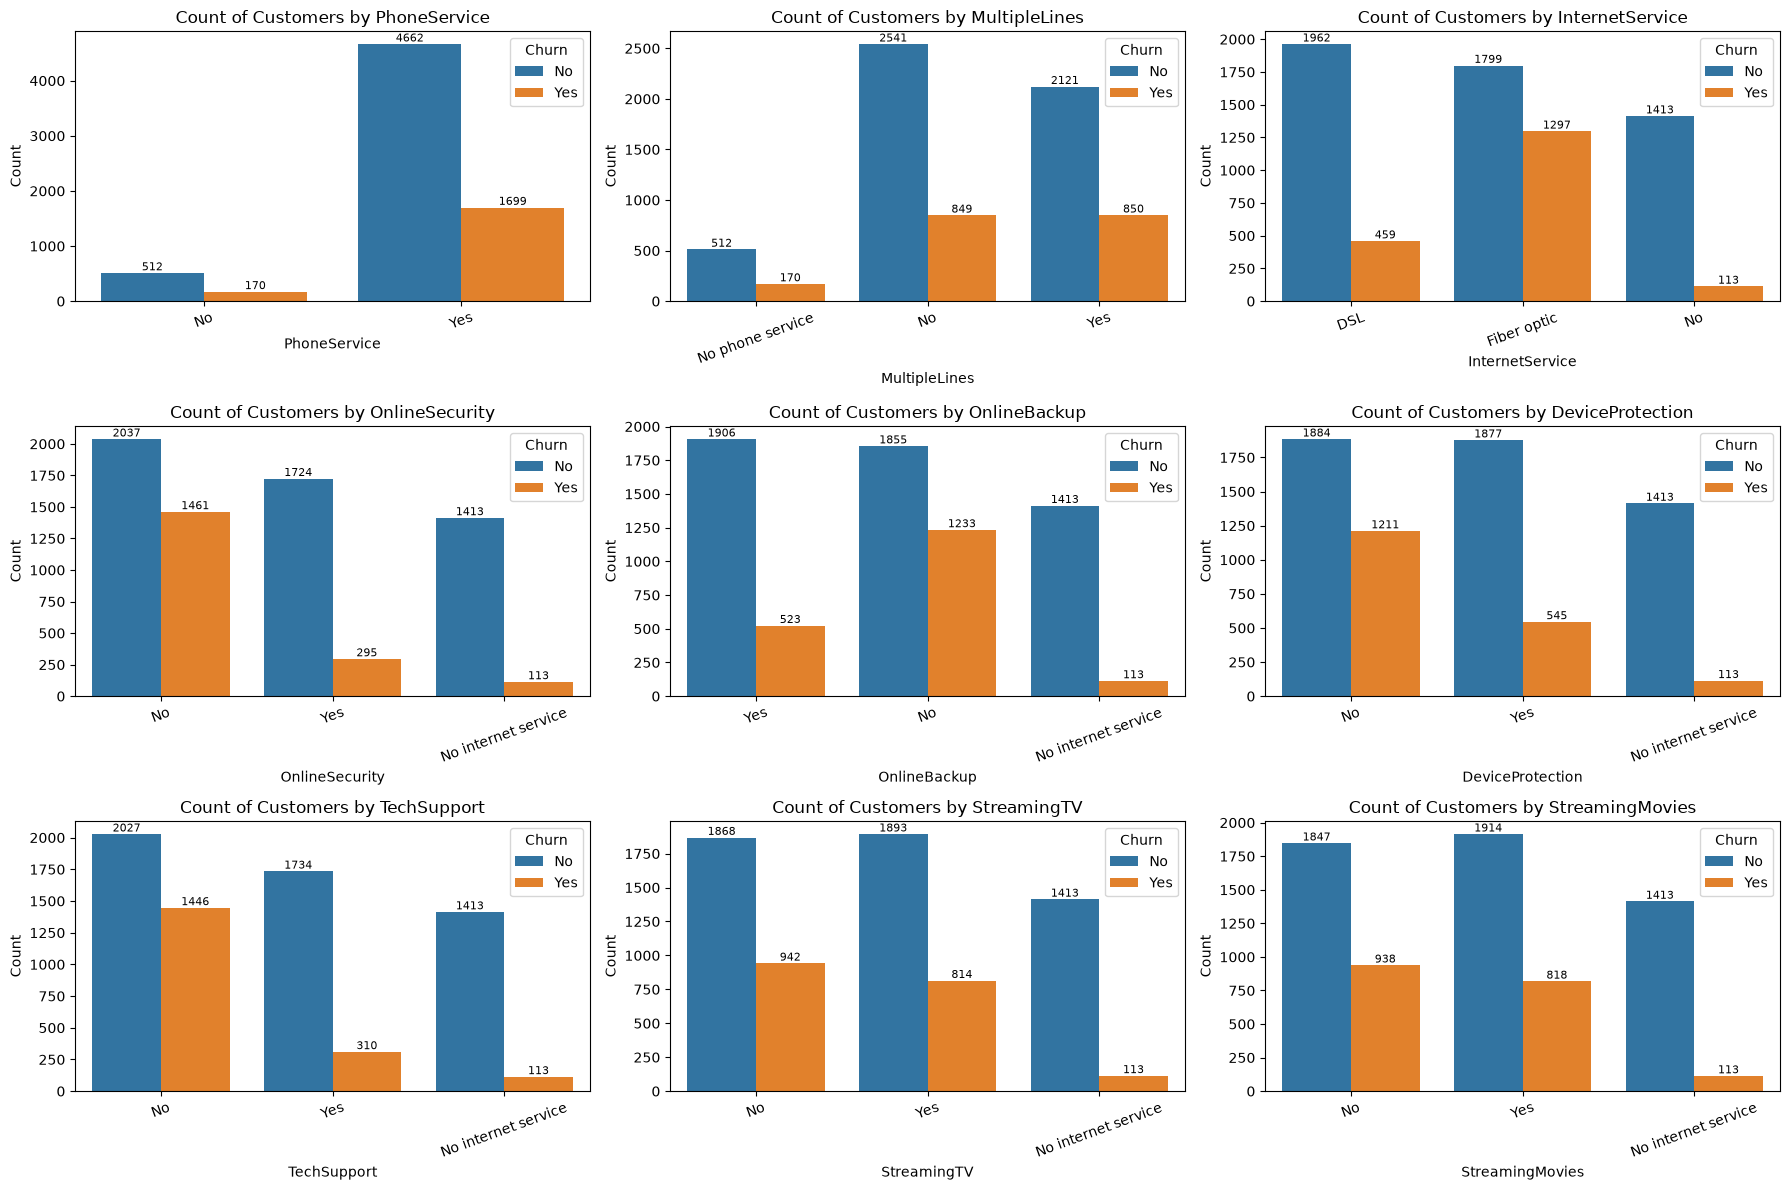

In [14]:
columns = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

axes = axes.flatten()

for i, col in enumerate(columns):
    sns.countplot(x=col, data=df, hue='Churn', ax=axes[i])

    axes[i].set_title(f'Count of Customers by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=20)

    for container in axes[i].containers:
        axes[i].bar_label(container, fontsize=8)

plt.tight_layout()
plt.show()

Customers who do not subscribe to additional services, particularly OnlineSecurity and TechSupport, tend to have higher churn. Fiber Optic internet users also account for a large number of churn cases. The company should focus on improving service quality, offering attractive service bundles, and providing better customer support to reduce customer churn.

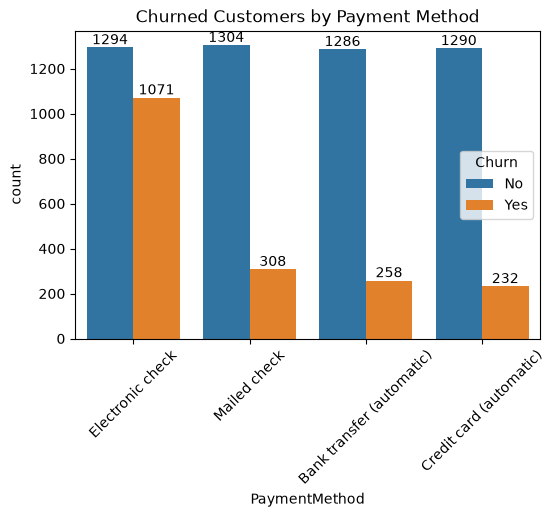

In [16]:
plt.figure(figsize = (6,4))
ax = sns.countplot(x = "PaymentMethod", data = df, hue = "Churn")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Churned Customers by Payment Method")
plt.xticks(rotation = 45)
plt.show()

## Conclusion: Customer Churn by Payment Method

- Electronic Check: Customers using electronic checks have the highest churn, with 1,071 customers leaving. This payment method appears to be associated with significantly higher churn.
- Mailed Check: Shows relatively low churn, with 308 customers leaving.
- Bank Transfer (Automatic): Has only 258 churned customers, indicating better customer retention.
- Credit Card (Automatic): Has the lowest churn, with 232 customers leaving.

### Overall Conclusion

Customers who use Electronic Check as their payment method are significantly more likely to churn compared to customers using automatic payment methods. In contrast, customers using automatic bank transfers and credit card payments show better retention.

Business Recommendation: The company should encourage customers to switch from electronic checks to automatic payment methods by offering incentives, discounts, or convenient payment options to reduce customer churn.